In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from mytorch import Tensor
from mytorch.layer import Linear
from mytorch.activation import relu, sigmoid
from mytorch.optimizer import SGD

In [2]:
#TODO
FILE_PATH = 'diabetes.csv'

In [3]:
#don't change this cell
column_names = [f"Feature_{i}" for i in range(1, 9)] + ["Diagnosis"]
df = pd.read_csv(FILE_PATH, header=1, names=column_names, usecols=range(0, 9))

# df["Diagnosis"] = df["Diagnosis"].map({"M": 1, "B": 0})

df.describe()

,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Feature_8,Diagnosis
count,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000
mean,3.842243,120.859192,69.101695,20.517601,79.903520,31.990482,0.471674,33.219035,0.348110
std,3.370877,31.978468,19.368155,15.954059,115.283105,7.889091,0.331497,11.752296,0.476682
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243500,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,32.000000,32.000000,0.371000,29.000000,0.000000
75%,6.000000,140.000000,80.000000,32.000000,127.500000,36.600000,0.625000,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [4]:
from torch.utils.data import TensorDataset

# Cell 5: Use numpy arrays instead of torch tensors
X = df.drop(columns=["Diagnosis"]).values.astype(np.float64)
y = df["Diagnosis"].values.astype(np.float64).reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# train_dataset = TensorDataset(X_train, y_train)
# test_dataset = TensorDataset(X_test, y_test)

In [5]:
# #TODO
# train_loader = DataLoader(train_dataset, batch_size=1024, shuffle=True)
# test_loader = DataLoader(test_dataset, batch_size=1024, shuffle=True)

In [6]:
class MLP:
    def __init__(self, input_size=8):
        self.fc1 = Linear(input_size, 128, need_bias=True)
        self.fc2 = Linear(128, 64, need_bias=True)
        self.fc3 = Linear(64, 32, need_bias=True)
        self.fc4 = Linear(32, 16, need_bias=True)
        self.fc5 = Linear(16, 1, need_bias=True)
        
        self.layers = [self.fc1, self.fc2, self.fc3, self.fc4, self.fc5]

    def forward(self, x: Tensor) -> Tensor:
        x = relu(self.fc1.forward(x))
        x = relu(self.fc2.forward(x))
        x = relu(self.fc3.forward(x))
        x = relu(self.fc4.forward(x))
        x = sigmoid(self.fc5.forward(x))
        return x

In [7]:
#TODO
input_size = X_train.shape[1]
model = MLP(input_size)
optimizer = SGD(model.layers, learning_rate=0.001)
NUM_EPOCHS = 1000

In [8]:
from mytorch.loss import CategoricalCrossEntropy
from mytorch.loss import MeanSquaredError

# Cell 9: Training loop with full-batch (manual, no DataLoader)
train_accuracy_list = []
test_accuracy_list = []

X_train_t = Tensor(X_train)
y_train_t = Tensor(y_train)

X_test_t = Tensor(X_test)
y_test_t = Tensor(y_test)

print(X_train_t.shape, y_train_t.shape)

for epoch in range(NUM_EPOCHS):
    # Train
    optimizer.zero_grad()
    outputs = model.forward(X_train_t)
    loss = CategoricalCrossEntropy(outputs, y_train_t)
    loss.backward()
    optimizer.step()
    
    # Train accuracy
    predicted = (outputs.data > 0.5).astype(float)
    corrects = (predicted == y_train).sum()
    accuracy = corrects / y_train.shape[0]
    train_accuracy_list.append(accuracy)
    print(f"Epoch {epoch+1}/{NUM_EPOCHS}, Loss: {loss.data:.4f}, Accuracy: {accuracy:.4f}")
    
    # Test (no grad)
    outputs_test = model.forward(X_test_t)
    predicted_test = (outputs_test.data > 0.5).astype(float)
    correct_test = (predicted_test == y_test).sum()
    accuracy_test = correct_test / y_test.shape[0]
    test_accuracy_list.append(accuracy_test)
    print(f"Test Accuracy: {accuracy_test:.4f}\n")

(613, 8) (613, 1)
Epoch 1/1000, Loss: 0.4114, Accuracy: 0.5661
Test Accuracy: 0.6104

Epoch 2/1000, Loss: 0.3261, Accuracy: 0.6460
Test Accuracy: 0.6299

Epoch 3/1000, Loss: 0.3053, Accuracy: 0.6493
Test Accuracy: 0.6364

Epoch 4/1000, Loss: 0.2998, Accuracy: 0.6493
Test Accuracy: 0.6234

Epoch 5/1000, Loss: 0.2979, Accuracy: 0.6493
Test Accuracy: 0.6104

Epoch 6/1000, Loss: 0.2967, Accuracy: 0.6493
Test Accuracy: 0.6299

Epoch 7/1000, Loss: 0.2957, Accuracy: 0.6525
Test Accuracy: 0.6299

Epoch 8/1000, Loss: 0.2946, Accuracy: 0.6542
Test Accuracy: 0.6299

Epoch 9/1000, Loss: 0.2937, Accuracy: 0.6525
Test Accuracy: 0.6299

Epoch 10/1000, Loss: 0.2928, Accuracy: 0.6509
Test Accuracy: 0.6299

Epoch 11/1000, Loss: 0.2920, Accuracy: 0.6509
Test Accuracy: 0.6299

Epoch 12/1000, Loss: 0.2913, Accuracy: 0.6525
Test Accuracy: 0.6299

Epoch 13/1000, Loss: 0.2905, Accuracy: 0.6542
Test Accuracy: 0.6299

Epoch 14/1000, Loss: 0.2898, Accuracy: 0.6558
Test Accuracy: 0.6299

Epoch 15/1000, Loss: 0.28

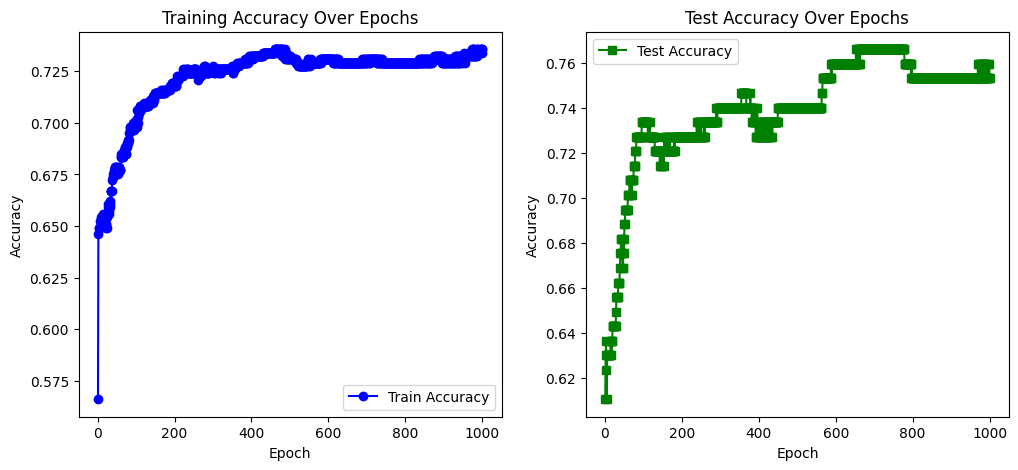

In [10]:

# don't change this cell
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, NUM_EPOCHS+1), train_accuracy_list, marker='o', linestyle='-', color='b', label="Train Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy Over Epochs")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, NUM_EPOCHS+1), test_accuracy_list, marker='s', linestyle='-', color='g', label="Test Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Test Accuracy Over Epochs")
plt.legend()

plt.show()